In [1]:

import os
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, ConfusionMatrixDisplay
)

SEED = 42
np.random.seed(SEED)
random.seed(SEED)

print("Libraries imported successfully.")
print("Random seed:", SEED)


Libraries imported successfully.
Random seed: 42



## 2. Upload the Dataset

Upload the supplied **`wdbc(1).data`** file when prompted.

The notebook automatically uses the uploaded `.data` or `.csv` file.


In [2]:

# Google Colab upload
try:
    from google.colab import files
    uploaded = files.upload()
    uploaded_names = list(uploaded.keys())
except ImportError:
    uploaded_names = []

# Try to identify the uploaded dataset automatically
candidate_files = uploaded_names + [
    "wdbc(1).data",
    "wdbc.data",
    "/content/wdbc(1).data",
    "/content/wdbc.data"
]

data_path = None
for f in candidate_files:
    if os.path.exists(f) and (str(f).lower().endswith(".data") or str(f).lower().endswith(".csv")):
        data_path = f
        break

if data_path is None:
    raise FileNotFoundError(
        "Dataset not found. Please upload 'wdbc(1).data' using the upload button above."
    )

print("Dataset selected:", data_path)


Saving wdbc.data to wdbc.data
Dataset selected: wdbc.data


In [3]:

feature_names = [
    "radius_mean", "texture_mean", "perimeter_mean", "area_mean", "smoothness_mean",
    "compactness_mean", "concavity_mean", "concave_points_mean", "symmetry_mean",
    "fractal_dimension_mean",

    "radius_se", "texture_se", "perimeter_se", "area_se", "smoothness_se",
    "compactness_se", "concavity_se", "concave_points_se", "symmetry_se",
    "fractal_dimension_se",

    "radius_worst", "texture_worst", "perimeter_worst", "area_worst", "smoothness_worst",
    "compactness_worst", "concavity_worst", "concave_points_worst", "symmetry_worst",
    "fractal_dimension_worst"
]

columns = ["id", "diagnosis"] + feature_names

df = pd.read_csv(data_path, header=None, names=columns)

print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())


Dataset loaded successfully.
Shape: (569, 32)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 4. Dataset Inspection

In [4]:

print("Dataset information:")
df.info()

print("\nMissing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

print("\nDiagnosis counts:")
print(df["diagnosis"].value_counts())

print("\nDiagnosis percentages:")
print((df["diagnosis"].value_counts(normalize=True) * 100).round(2).astype(str) + "%")


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perim

In [5]:

# Descriptive statistics for the numeric predictors
display(df.drop(columns=["id"]).describe().T.round(3))


,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
texture_mean,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
perimeter_mean,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
area_mean,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
smoothness_mean,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
compactness_mean,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
concavity_mean,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
concave_points_mean,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
symmetry_mean,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
fractal_dimension_mean,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


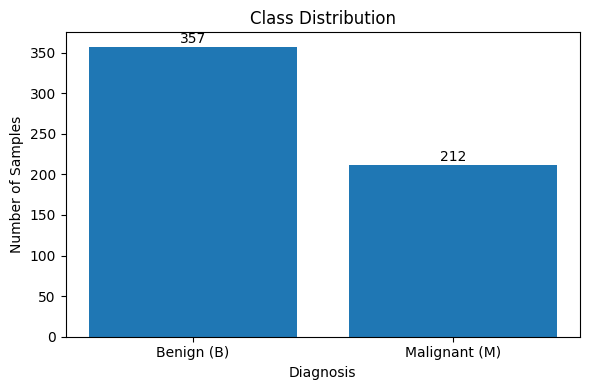

In [6]:

# Class distribution
class_counts = df["diagnosis"].value_counts().reindex(["B", "M"])

plt.figure(figsize=(6, 4))
plt.bar(["Benign (B)", "Malignant (M)"], class_counts.values)
plt.title("Class Distribution")
plt.ylabel("Number of Samples")
plt.xlabel("Diagnosis")
for i, value in enumerate(class_counts.values):
    plt.text(i, value + 5, str(value), ha="center")
plt.tight_layout()
plt.show()


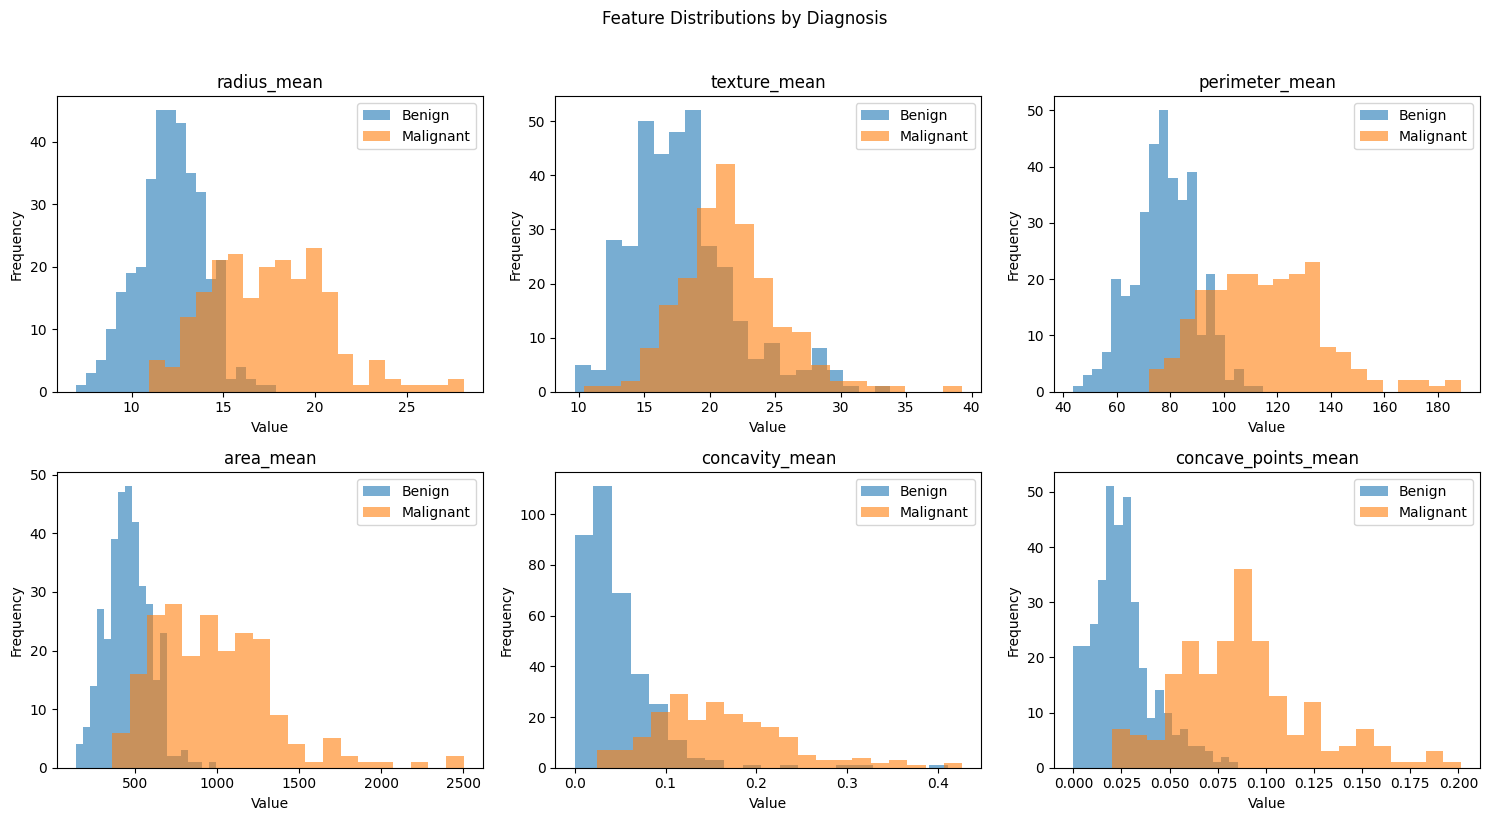

In [7]:

# Compare selected clinically informative variables by diagnosis
selected_eda_features = [
    "radius_mean", "texture_mean", "perimeter_mean",
    "area_mean", "concavity_mean", "concave_points_mean"
]

df_plot = df.copy()
df_plot["diagnosis_numeric"] = df_plot["diagnosis"].map({"B": 0, "M": 1})

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, feature in zip(axes, selected_eda_features):
    benign = df_plot.loc[df_plot["diagnosis"] == "B", feature]
    malignant = df_plot.loc[df_plot["diagnosis"] == "M", feature]
    ax.hist(benign, bins=20, alpha=0.6, label="Benign")
    ax.hist(malignant, bins=20, alpha=0.6, label="Malignant")
    ax.set_title(feature)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")
    ax.legend()

plt.suptitle("Feature Distributions by Diagnosis", y=1.02)
plt.tight_layout()
plt.show()


In [8]:

# Correlation of each feature with the target
corr_df = df.copy()
corr_df["diagnosis"] = corr_df["diagnosis"].map({"B": 0, "M": 1})
target_correlations = (
    corr_df.drop(columns=["id"])
           .corr(numeric_only=True)["diagnosis"]
           .drop("diagnosis")
           .abs()
           .sort_values(ascending=False)
)

print("Top 10 features by absolute correlation with diagnosis:")
display(target_correlations.head(10).to_frame("Absolute Correlation"))


Top 10 features by absolute correlation with diagnosis:


,Absolute Correlation
concave_points_worst,0.793566
perimeter_worst,0.782914
concave_points_mean,0.776614
radius_worst,0.776454
perimeter_mean,0.742636
area_worst,0.733825
radius_mean,0.730029
area_mean,0.708984
concavity_mean,0.696360
concavity_worst,0.659610


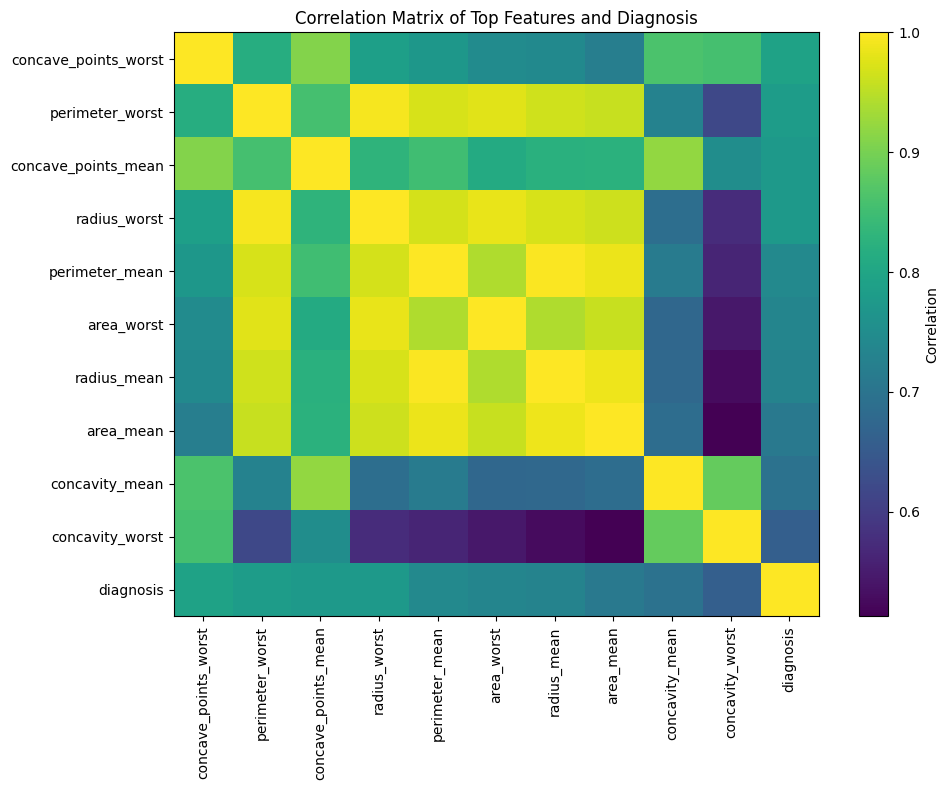

In [9]:

# Correlation heatmap for the 10 strongest features
top10_features = target_correlations.head(10).index.tolist()
corr_matrix = corr_df[top10_features + ["diagnosis"]].corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr_matrix, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=90)
plt.yticks(range(len(corr_matrix.index)), corr_matrix.index)
plt.title("Correlation Matrix of Top Features and Diagnosis")
plt.tight_layout()
plt.show()



## 6. Data Preparation

### Processing decisions
- `id` is removed because it is an identifier rather than a predictive measurement.
- `M` is encoded as `1` and `B` as `0`.
- The data are split into **80% training** and **20% testing** using stratification.
- Feature selection is learned **only from the training data** to avoid information leakage.
- The same selected features are used across all models for a fair comparison.
- Standardisation is used for Logistic Regression and ANN.


In [10]:

# Encode diagnosis
model_df = df.copy()
model_df["diagnosis"] = model_df["diagnosis"].map({"B": 0, "M": 1})

X = model_df.drop(columns=["id", "diagnosis"])
y = model_df["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))


Training set: (455, 30)
Testing set : (114, 30)

Training target distribution:
diagnosis
0    0.626
1    0.374
Name: proportion, dtype: float64

Testing target distribution:
diagnosis
0    0.632
1    0.368
Name: proportion, dtype: float64


In [11]:

K = 15

selector = SelectKBest(score_func=f_classif, k=K)
selector.fit(X_train, y_train)

selected_mask = selector.get_support()
selected_features = X_train.columns[selected_mask].tolist()

feature_scores = pd.DataFrame({
    "Feature": X_train.columns,
    "F_Score": selector.scores_
}).sort_values("F_Score", ascending=False)

print(f"Selected {K} features:")
print(selected_features)

print("\nTop feature-selection scores:")
display(feature_scores.head(15).reset_index(drop=True))


Selected 15 features:
['radius_mean', 'perimeter_mean', 'area_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'radius_se', 'perimeter_se', 'area_se', 'radius_worst', 'perimeter_worst', 'area_worst', 'compactness_worst', 'concavity_worst', 'concave_points_worst']

Top feature-selection scores:


,Feature,F_Score
0,concave_points_worst,733.724933
1,perimeter_worst,717.246487
2,radius_worst,692.861395
3,concave_points_mean,684.526845
4,perimeter_mean,548.413236
5,area_worst,522.188947
6,radius_mean,511.274848
7,area_mean,444.857518
8,concavity_mean,397.592082
9,concavity_worst,319.507776


In [12]:

# Transform train/test sets using feature selector
X_train_sel = selector.transform(X_train)
X_test_sel = selector.transform(X_test)

# Standardise selected features for ANN and Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_sel)
X_test_scaled = scaler.transform(X_test_sel)

print("Selected training matrix:", X_train_sel.shape)
print("Scaled training matrix:", X_train_scaled.shape)


Selected training matrix: (455, 15)
Scaled training matrix: (455, 15)



## 8. Model Training

Four required models are developed:
- Decision Tree
- Random Forest
- Gaussian Naïve Bayes
- Multilayer ANN

Logistic Regression is included as an additional benchmark.

All final performance values are calculated on the same unseen test set.


In [13]:

# Classical machine-learning models
decision_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    min_samples_split=4,
    random_state=SEED
)

random_forest = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1
)

naive_bayes = GaussianNB()

logistic_regression = LogisticRegression(
    max_iter=5000,
    class_weight="balanced",
    random_state=SEED
)

# Train models
decision_tree.fit(X_train_sel, y_train)
random_forest.fit(X_train_sel, y_train)
naive_bayes.fit(X_train_sel, y_train)
logistic_regression.fit(X_train_scaled, y_train)

print("Classical models trained successfully.")


Classical models trained successfully.


In [14]:

# Import TensorFlow/Keras
try:
    import tensorflow as tf
except ImportError:
    print("TensorFlow is not installed. Installing it now...")
    !pip -q install tensorflow
    import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(SEED)

ann = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(64, activation="relu"),
    Dropout(0.25),
    Dense(32, activation="relu"),
    Dropout(0.20),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

ann.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

ann.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,649 (14.25 KB)

 Trainable params: 3,649 (14.25 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True,
    verbose=1
)

history = ann.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=150,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=0
)

print("ANN training completed.")
print("Epochs completed:", len(history.history["loss"]))


Epoch 21: early stopping
Restoring model weights from the end of the best epoch: 6.
ANN training completed.
Epochs completed: 21


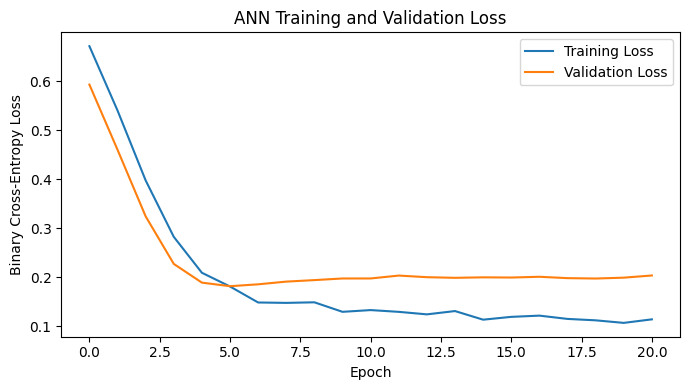

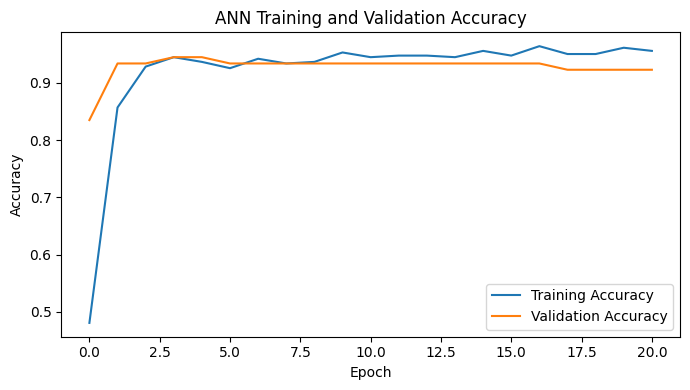

In [16]:

# ANN learning curves
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("ANN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("ANN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()


## 10. Test-Set Predictions and Evaluation

In [17]:

# Probability predictions
dt_prob = decision_tree.predict_proba(X_test_sel)[:, 1]
rf_prob = random_forest.predict_proba(X_test_sel)[:, 1]
nb_prob = naive_bayes.predict_proba(X_test_sel)[:, 1]
lr_prob = logistic_regression.predict_proba(X_test_scaled)[:, 1]
ann_prob = ann.predict(X_test_scaled, verbose=0).ravel()

# Class predictions
dt_pred = (dt_prob >= 0.5).astype(int)
rf_pred = (rf_prob >= 0.5).astype(int)
nb_pred = (nb_prob >= 0.5).astype(int)
lr_pred = (lr_prob >= 0.5).astype(int)
ann_pred = (ann_prob >= 0.5).astype(int)

predictions = {
    "Decision Tree": (dt_pred, dt_prob),
    "Random Forest": (rf_pred, rf_prob),
    "Naive Bayes": (nb_pred, nb_prob),
    "Logistic Regression": (lr_pred, lr_prob),
    "Multilayer ANN": (ann_pred, ann_prob)
}

def evaluate_model(name, y_true, y_pred, y_prob):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

results = []
for name, (pred, prob) in predictions.items():
    results.append(evaluate_model(name, y_test, pred, prob))

results_df = pd.DataFrame(results).sort_values(
    by=["F1-Score", "ROC-AUC"],
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.9825,0.9762,0.9762,0.9762,0.9993
1,Multilayer ANN,0.9561,0.9744,0.9048,0.9383,0.9974
2,Random Forest,0.9561,1.0000,0.8810,0.9367,0.9939
3,Decision Tree,0.9474,0.9737,0.8810,0.9250,0.9439
4,Naive Bayes,0.9298,0.9722,0.8333,0.8974,0.9924


In [18]:

for name, (pred, prob) in predictions.items():
    print("=" * 70)
    print(name)
    print("=" * 70)
    print(classification_report(
        y_test,
        pred,
        target_names=["Benign", "Malignant"],
        digits=4
    ))


Decision Tree
              precision    recall  f1-score   support

      Benign     0.9342    0.9861    0.9595        72
   Malignant     0.9737    0.8810    0.9250        42

    accuracy                         0.9474       114
   macro avg     0.9539    0.9335    0.9422       114
weighted avg     0.9488    0.9474    0.9468       114

Random Forest
              precision    recall  f1-score   support

      Benign     0.9351    1.0000    0.9664        72
   Malignant     1.0000    0.8810    0.9367        42

    accuracy                         0.9561       114
   macro avg     0.9675    0.9405    0.9516       114
weighted avg     0.9590    0.9561    0.9555       114

Naive Bayes
              precision    recall  f1-score   support

      Benign     0.9103    0.9861    0.9467        72
   Malignant     0.9722    0.8333    0.8974        42

    accuracy                         0.9298       114
   macro avg     0.9412    0.9097    0.9221       114
weighted avg     0.9331    0.9298 

## 11. Confusion Matrices

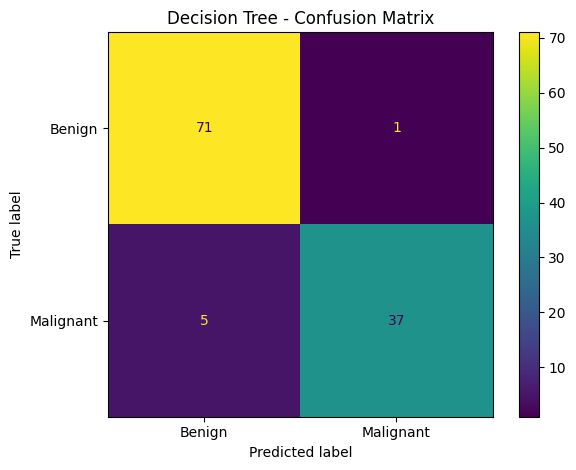

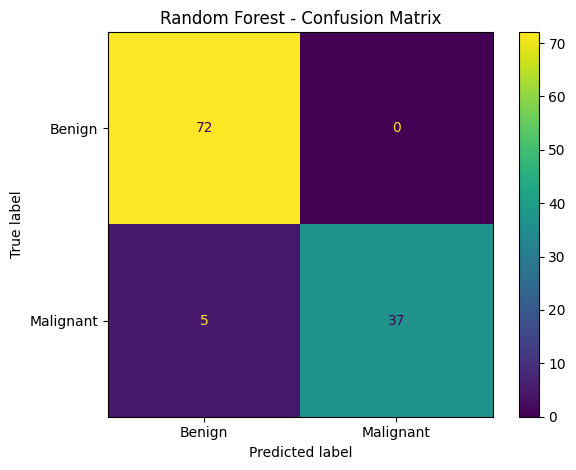

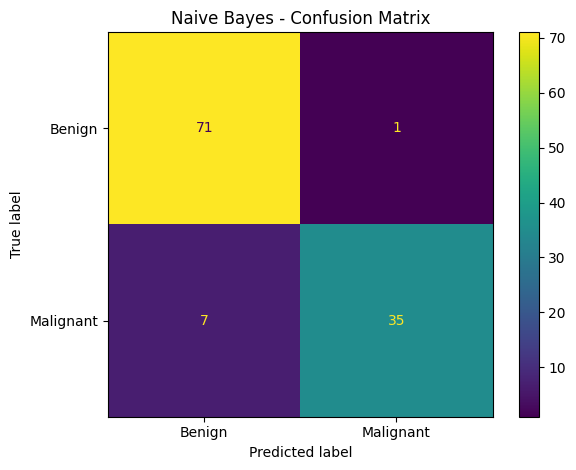

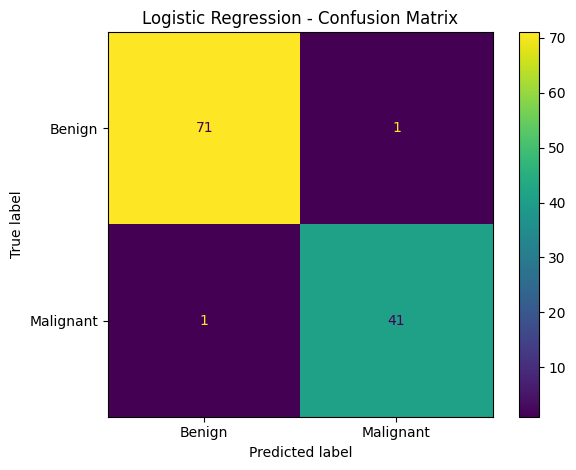

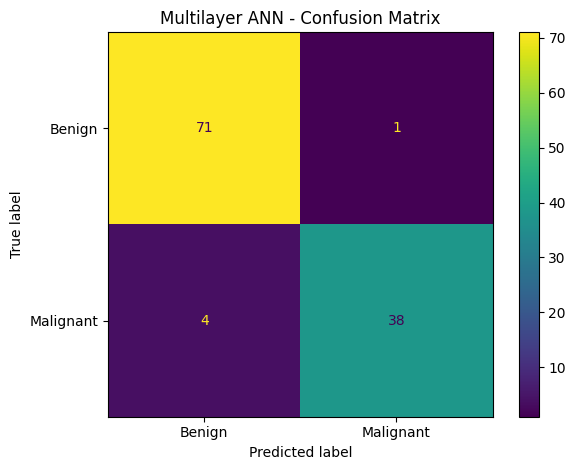

In [19]:

for name, (pred, prob) in predictions.items():
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Benign", "Malignant"]
    )
    disp.plot(values_format="d")
    plt.title(f"{name} - Confusion Matrix")
    plt.tight_layout()
    plt.show()


## 12. ROC Curves

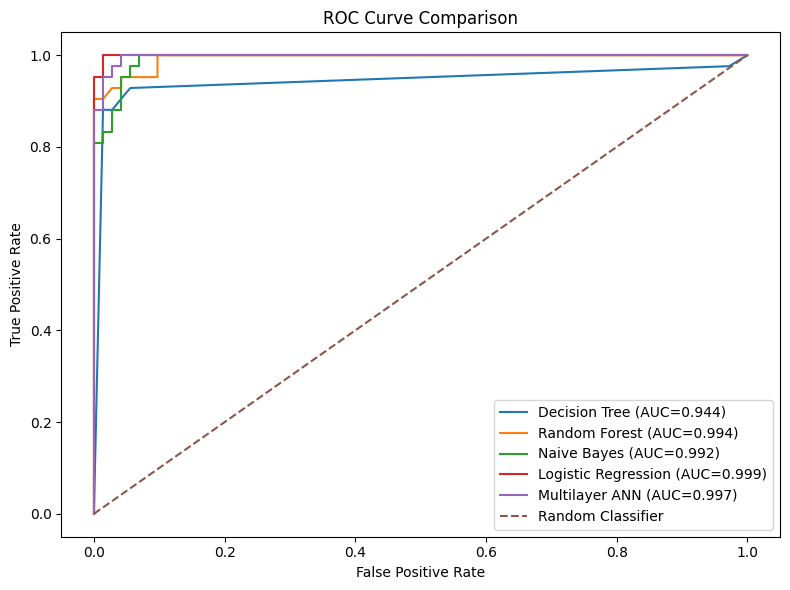

In [20]:

plt.figure(figsize=(8, 6))

for name, (pred, prob) in predictions.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc_value = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_value:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.tight_layout()
plt.show()


## 13. Visual Comparison of Model Performance

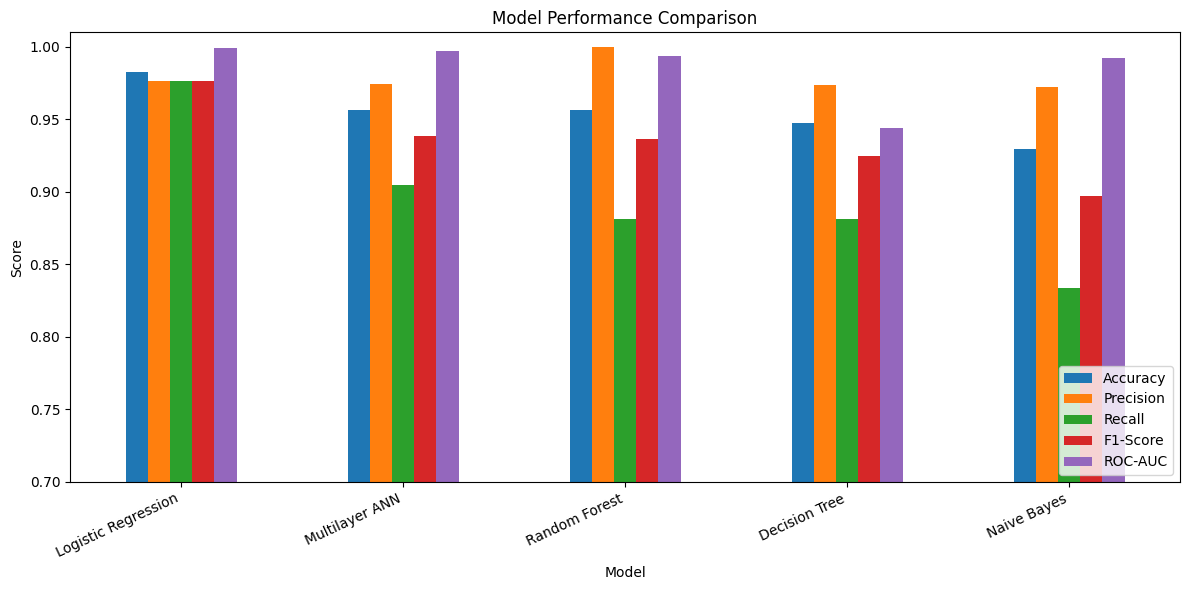

In [21]:

metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

plot_df = results_df.set_index("Model")[metrics_to_plot]

ax = plot_df.plot(kind="bar", figsize=(12, 6))
plt.ylim(0.70, 1.01)
plt.ylabel("Score")
plt.title("Model Performance Comparison")
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()



## 14. Cross-Validation of Classical Models

Five-fold stratified cross-validation is used on the training data to provide an additional robustness check.

The test set remains untouched and is still the primary basis for final comparison.


In [22]:

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# To avoid leakage during CV, perform feature selection inside each fold manually
from sklearn.pipeline import Pipeline

cv_models = {
    "Decision Tree": Pipeline([
        ("select", SelectKBest(f_classif, k=K)),
        ("model", DecisionTreeClassifier(
            criterion="gini",
            max_depth=5,
            min_samples_split=4,
            random_state=SEED
        ))
    ]),

    "Random Forest": Pipeline([
        ("select", SelectKBest(f_classif, k=K)),
        ("model", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=SEED,
            n_jobs=-1
        ))
    ]),

    "Naive Bayes": Pipeline([
        ("select", SelectKBest(f_classif, k=K)),
        ("model", GaussianNB())
    ]),

    "Logistic Regression": Pipeline([
        ("select", SelectKBest(f_classif, k=K)),
        ("scale", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=5000,
            class_weight="balanced",
            random_state=SEED
        ))
    ])
}

cv_results = []

for name, model in cv_models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1"
    )
    cv_results.append({
        "Model": name,
        "Mean CV F1": scores.mean(),
        "CV Std": scores.std()
    })

cv_results_df = pd.DataFrame(cv_results).sort_values(
    "Mean CV F1", ascending=False
).reset_index(drop=True)

display(cv_results_df.round(4))


,Model,Mean CV F1,CV Std
0,Random Forest,0.9257,0.0269
1,Logistic Regression,0.9254,0.0377
2,Decision Tree,0.9000,0.0316
3,Naive Bayes,0.8988,0.0394


## 15. Random Forest Feature Importance

,Feature,Importance
0,perimeter_worst,0.179801
1,concave_points_worst,0.120306
2,concave_points_mean,0.119490
3,radius_worst,0.113628
4,area_worst,0.105021
5,concavity_mean,0.066809
6,area_mean,0.056084
7,concavity_worst,0.050044
8,perimeter_mean,0.046049
9,radius_mean,0.045696


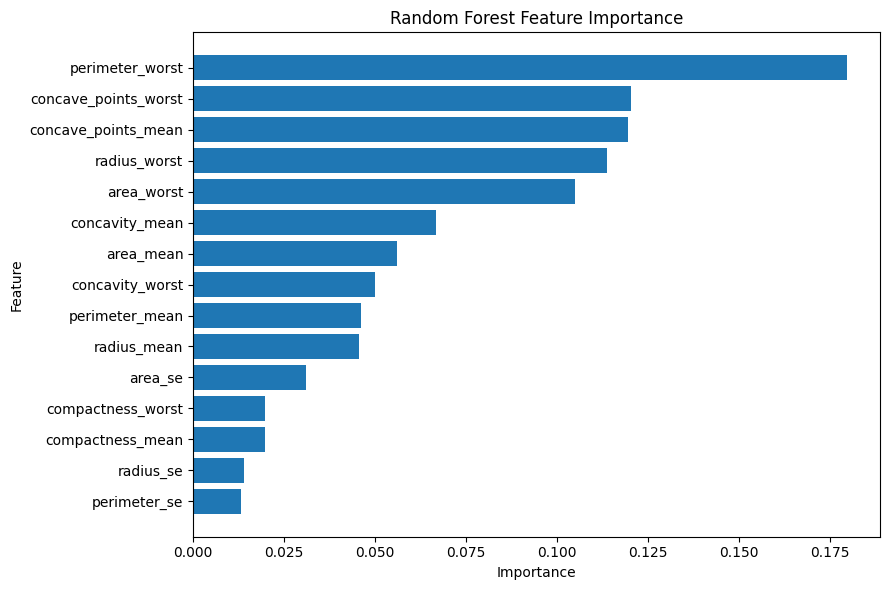

In [23]:

rf_importance = pd.DataFrame({
    "Feature": selected_features,
    "Importance": random_forest.feature_importances_
}).sort_values("Importance", ascending=False)

display(rf_importance.reset_index(drop=True))

plt.figure(figsize=(9, 6))
plt.barh(
    rf_importance["Feature"].iloc[::-1],
    rf_importance["Importance"].iloc[::-1]
)
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [24]:

best_row = results_df.iloc[0]

print("FINAL TEST-SET SUMMARY")
print("-" * 60)
print("Highest observed F1 model:", best_row["Model"])
print(f"Accuracy : {best_row['Accuracy']:.4f}")
print(f"Precision: {best_row['Precision']:.4f}")
print(f"Recall   : {best_row['Recall']:.4f}")
print(f"F1-Score : {best_row['F1-Score']:.4f}")
print(f"ROC-AUC  : {best_row['ROC-AUC']:.4f}")

print("\nComplete ranking:")
display(results_df.round(4))


FINAL TEST-SET SUMMARY
------------------------------------------------------------
Highest observed F1 model: Logistic Regression
Accuracy : 0.9825
Precision: 0.9762
Recall   : 0.9762
F1-Score : 0.9762
ROC-AUC  : 0.9993

Complete ranking:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.9825,0.9762,0.9762,0.9762,0.9993
1,Multilayer ANN,0.9561,0.9744,0.9048,0.9383,0.9974
2,Random Forest,0.9561,1.0000,0.8810,0.9367,0.9939
3,Decision Tree,0.9474,0.9737,0.8810,0.9250,0.9439
4,Naive Bayes,0.9298,0.9722,0.8333,0.8974,0.9924
